# Telco Customer Churn — Baseline Experiments



# EDA for Telco-Customer-Churn.csv


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"


telco_path = RAW_DIR / "Telco-Customer-Churn.csv"

telco_df = pd.read_csv(telco_path)

print("Dataset Shape:", telco_df.shape)


Dataset Shape: (7043, 21)


In [3]:
print("\nFirst 5 Rows:")
display(telco_df.head())


First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("\nColumn Names:")
print(telco_df.columns.tolist())




Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:

print("\nData Types:")
print(telco_df.dtypes)




Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [6]:

print("\nDataset Information:")
telco_df.info()




Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

In [7]:
print("\nMissing Values:")
print(telco_df.isnull().sum())



Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [8]:

print("\nDuplicate Rows:", telco_df.duplicated().sum())


Duplicate Rows: 0


# Churn Dustribution

In [9]:
print("Target Column Distribution:")
print(telco_df["Churn"].value_counts())

print("\nTarget Column Percentage:")
print(telco_df["Churn"].value_counts(normalize=True) * 100)

print("\nTarget Data Type:")
print(telco_df["Churn"].dtype)

Target Column Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target Column Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Target Data Type:
str


# Feature Engineering

In [10]:
print("Dataset Columns:")
for column in telco_df.columns:
    print(column)

print("\nUnique Values in Target:")
print(telco_df["Churn"].unique())

print("\nCustomer ID Unique Count:")
print(telco_df["customerID"].nunique())

Dataset Columns:
customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn

Unique Values in Target:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Customer ID Unique Count:
7043


In [11]:
print("TotalCharges Data Type:")
print(telco_df["TotalCharges"].dtype)

print("\nTotalCharges Non-Numeric Values:")
total_charges_numeric = pd.to_numeric(
    telco_df["TotalCharges"],
    errors="coerce"
)

print("Non-numeric count:", total_charges_numeric.isna().sum())

print("\nTenure Summary:")
print(telco_df["tenure"].describe())

TotalCharges Data Type:
str

TotalCharges Non-Numeric Values:
Non-numeric count: 11

Tenure Summary:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


# Handle Missing value of TotalCharges

In [12]:
total_charges_numeric = pd.to_numeric(
    telco_df["TotalCharges"],
    errors="coerce"
)

invalid_total_charges = telco_df.loc[
    total_charges_numeric.isna(),
    ["customerID", "tenure", "TotalCharges", "Churn"]
]

print("Invalid TotalCharges Rows:")
display(invalid_total_charges)

print("\nOriginal Values Representations:")
print(
    telco_df.loc[
        total_charges_numeric.isna(),
        "TotalCharges"
    ].map(repr).value_counts()
)

Invalid TotalCharges Rows:


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No



Original Values Representations:
TotalCharges
' '    11
Name: count, dtype: int64


now observing the table totalcharges are empty for customer who have tenure 0 and they have not churned yet so we can replace totalcharge with 0

In [13]:
telco_clean_df = telco_df.copy()

telco_clean_df["TotalCharges"] = pd.to_numeric(
    telco_clean_df["TotalCharges"].replace(r"^\s*$", pd.NA, regex=True),
    errors="coerce"
)

zero_tenure_mask = telco_clean_df["tenure"].eq(0)

telco_clean_df.loc[
    zero_tenure_mask & telco_clean_df["TotalCharges"].isna(),
    "TotalCharges"
] = 0

print("Original Shape:", telco_df.shape)
print("Cleaned Shape:", telco_clean_df.shape)

print("\nTotalCharges Data Type:")
print(telco_clean_df["TotalCharges"].dtype)

print("\nRemaining Missing Values:")
print(telco_clean_df.isnull().sum())

print("\nTotalCharges Summary:")
print(telco_clean_df["TotalCharges"].describe())

Original Shape: (7043, 21)
Cleaned Shape: (7043, 21)

TotalCharges Data Type:
float64

Remaining Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges Summary:
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


# Separating targets and Features

In [14]:
X = telco_clean_df.drop(columns=["Churn", "customerID"])
y = telco_clean_df["Churn"].map({"No": 0, "Yes": 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Data Type:", y.dtype)

print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target Data Type: int64

Feature Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [15]:

from pathlib import Path

clean_dir = PROJECT_ROOT / "data" / "processed"
clean_dir.mkdir(parents=True, exist_ok=True)

clean_path = clean_dir / "Telco-Customer-Churn-Cleaned.csv"

telco_clean_df.to_csv(clean_path, index=False)

print("Cleaned dataset saved successfully!")
print("File Path:", clean_path.resolve())
print("Saved Dataset Shape:", telco_clean_df.shape)


Cleaned dataset saved successfully!
File Path: C:\Users\Acer\Desktop\customer-churn-retention-mvp\data\processed\Telco-Customer-Churn-Cleaned.csv
Saved Dataset Shape: (7043, 21)


# Train_Test_split

In [16]:
from sklearn.model_selection import train_test_split

# 70% training, 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Temporary data nu 15% validation te 15% testing vich vandna
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Set:", X_train.shape, y_train.shape)
print("Validation Set:", X_val.shape, y_val.shape)
print("Testing Set:", X_test.shape, y_test.shape)

print("\nChurn Ratio in Each Set:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Training Set: (4930, 19) (4930,)
Validation Set: (1056, 19) (1056,)
Testing Set: (1057, 19) (1057,)

Churn Ratio in Each Set:
Train: 26.53 %
Validation: 26.52 %
Test: 26.58 %


# PreProcessing

In [17]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["object", "category", "str"]).columns.tolist()

print("Numeric Features:", numeric_features)
print("\nNumeric Feature Count:", len(numeric_features))

print("\nCategorical Features:", categorical_features)
print("\nCategorical Feature Count:", len(categorical_features))

Numeric Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Numeric Feature Count: 4

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Categorical Feature Count: 15


# Preprocessing Pipeline

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


# Baseline Logistic Regression model

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

grid_search_lr = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid_lr,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_lr.fit(X_train, y_train)

best_logistic_model = grid_search_lr.best_estimator_

print("Best Parameters:")
print(grid_search_lr.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(grid_search_lr.best_score_, 4))

y_val_prob_lr_tuned = best_logistic_model.predict_proba(X_val)[:, 1]
y_val_pred_lr_tuned = best_logistic_model.predict(X_val)

print("\nTuned Logistic Regression — Validation Results")
print(classification_report(y_val, y_val_pred_lr_tuned))
print(
    "Validation ROC-AUC:",
    round(roc_auc_score(y_val, y_val_prob_lr_tuned), 4)
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:
{'classifier__C': 10, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Best Cross-Validation ROC-AUC:
0.8458

Tuned Logistic Regression — Validation Results
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       776
           1       0.65      0.59      0.62       280

    accuracy                           0.81      1056
   macro avg       0.75      0.74      0.74      1056
weighted avg       0.80      0.81      0.80      1056

Validation ROC-AUC: 0.8454


# Baseline Random Forest model

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

param_grid_rf = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__class_weight": [None, "balanced"]
}

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

best_rf_model = grid_search_rf.best_estimator_

print("Best Parameters:")
print(grid_search_rf.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(grid_search_rf.best_score_, 4))

y_val_prob_rf_tuned = best_rf_model.predict_proba(X_val)[:, 1]
y_val_pred_rf_tuned = best_rf_model.predict(X_val)

print("\nTuned Random Forest — Validation Results")
print(classification_report(y_val, y_val_pred_rf_tuned))

print(
    "Validation ROC-AUC:",
    round(roc_auc_score(y_val, y_val_prob_rf_tuned), 4)
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.8469

Tuned Random Forest — Validation Results
              precision    recall  f1-score   support

           0       0.91      0.75      0.82       776
           1       0.53      0.79      0.63       280

    accuracy                           0.76      1056
   macro avg       0.72      0.77      0.73      1056
weighted avg       0.81      0.76      0.77      1056

Validation ROC-AUC: 0.8411


# Comparing Model

In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for model_name, probabilities in [
    ("Logistic Regression", y_val_prob_lr_tuned),
    ("Random Forest", y_val_prob_rf_tuned)
]:
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "model": model_name,
            "threshold": threshold,
            "accuracy": accuracy_score(y_val, predictions),
            "churn_precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "churn_recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "churn_f1": f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        ["model", "threshold"]
    ).round(4)
)

,model,threshold,accuracy,churn_precision,churn_recall,churn_f1
0,Logistic Regression,0.30,0.7491,0.5176,0.7893,0.6252
1,Logistic Regression,0.35,0.7604,0.5345,0.7464,0.6230
2,Logistic Regression,0.40,0.7775,0.5645,0.7036,0.6264
3,Logistic Regression,0.45,0.7898,0.5942,0.6536,0.6224
4,Logistic Regression,0.50,0.8068,0.6484,0.5929,0.6194
5,Logistic Regression,0.55,0.8078,0.6808,0.5179,0.5882
6,Logistic Regression,0.60,0.8021,0.7178,0.4179,0.5282
7,Random Forest,0.30,0.6610,0.4337,0.9107,0.5876
8,Random Forest,0.35,0.6884,0.4552,0.8893,0.6022
9,Random Forest,0.40,0.7206,0.4848,0.8571,0.6194


### Primary Model Selection: Logistic Regression

After comparing the tuned Logistic Regression and Random Forest models on the validation dataset, Logistic Regression was selected as the primary model candidate for the Customer Churn & Retention Through Fulfilment Intelligence project.

**Reasons for Selection:**

- **Validation Accuracy:** 80.68% at the default threshold of 0.50.
- **Validation ROC-AUC:** 0.8454, compared with 0.8411 for tuned Random Forest.
- **Churn Precision:** 64.84% at the default threshold of 0.50.
- **Interpretability:** Logistic Regression provides interpretable coefficients that help explain factors influencing customer churn.

**Provisional Decision Threshold: 0.40**

Based on the validation results, a threshold of 0.40 was provisionally selected for Logistic Regression.

- **Accuracy:** 77.75%
- **Churn Precision:** 56.45%
- **Churn Recall:** 70.36%
- **Churn F1-score:** 0.6264

Compared with the default threshold of 0.50, the 0.40 threshold identifies more potential churners, with higher recall, while maintaining a reasonable F1-score.

**Random Forest Comparison:**

Random Forest achieved an F1-score of 0.6373 and recall of 75% at a threshold of 0.55. It remains the comparison model.

**Final Decision:** Logistic Regression is the primary model candidate, with 0.40 as its provisional threshold. Final model performance and threshold selection will be confirmed after evaluation on the untouched test dataset.

# Final Model

In [22]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# final test predictions using the selected threshold
test_probabilities = best_logistic_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.40).astype(int)

# evaluation metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_roc_auc = roc_auc_score(y_test, test_probabilities)

print("Logistic Regression - Final Test Results")
print("-" * 45)
print(f"Accuracy: {test_accuracy:.4f}")
print(f"ROC-AUC:  {test_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No Churn", "Churn"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

Logistic Regression - Final Test Results
---------------------------------------------
Accuracy: 0.7890
ROC-AUC:  0.8448

Classification Report:
              precision    recall  f1-score   support

    No Churn     0.8701    0.8376    0.8536       776
       Churn     0.5935    0.6548    0.6227       281

    accuracy                         0.7890      1057
   macro avg     0.7318    0.7462    0.7381      1057
weighted avg     0.7966    0.7890    0.7922      1057

Confusion Matrix:
[[650 126]
 [ 97 184]]


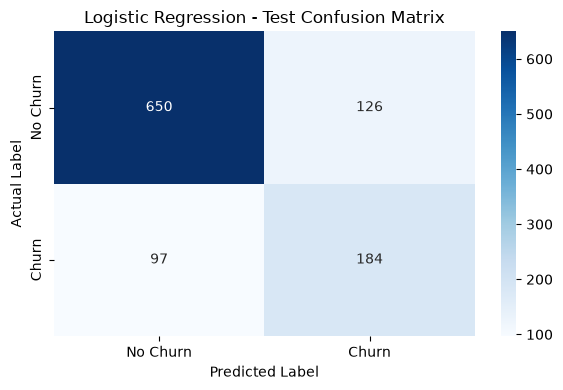

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# SHAP


In [24]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


c:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
import shap

explainer = shap.Explainer(
    best_logistic_model.named_steps["classifier"],
    best_logistic_model.named_steps["preprocessor"].transform(X_train)
)

X_test_transformed = best_logistic_model.named_steps["preprocessor"].transform(X_test)

shap_values = explainer(X_test_transformed)

print("SHAP explanation generated successfully.")
print("Test data shape:", X_test_transformed.shape)
print("SHAP values shape:", shap_values.values.shape)

Background dataset has 4930 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4930 when initializing the masker.


SHAP explanation generated successfully.
Test data shape: (1057, 45)
SHAP values shape: (1057, 45)


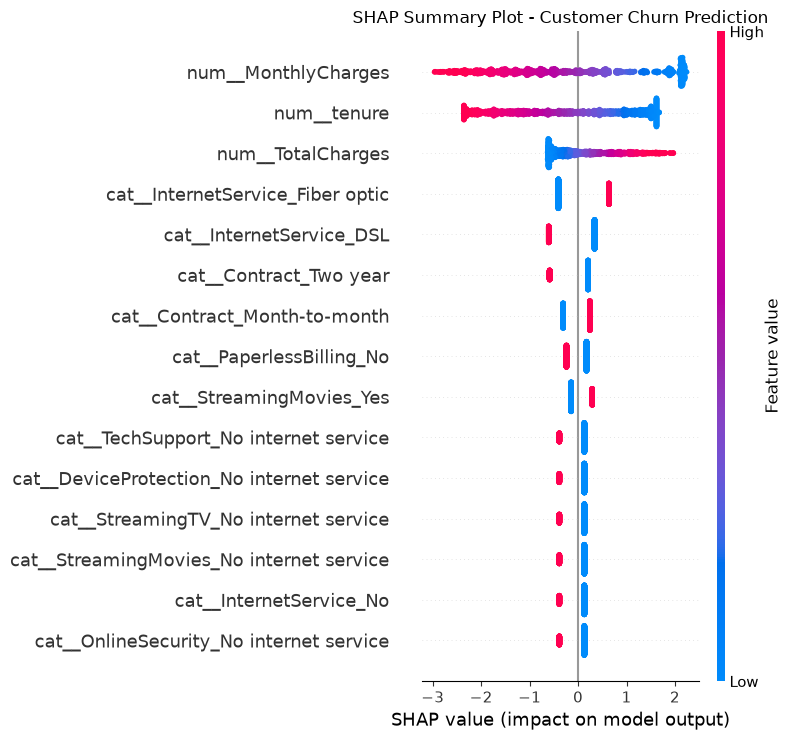

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

feature_names = best_logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

shap.summary_plot(
    shap_values.values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Customer Churn Prediction")
plt.tight_layout()
plt.show()

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": np.abs(shap_values.values).mean(axis=0)
})

feature_importance_df = feature_importance_df.sort_values(
    by="mean_absolute_shap",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(15))

,feature,mean_absolute_shap
0,num__MonthlyCharges,1.380858
1,num__tenure,1.221458
2,num__TotalCharges,0.548976
3,cat__InternetService_Fiber optic,0.502786
4,cat__InternetService_DSL,0.434994
5,cat__Contract_Two year,0.298158
6,cat__Contract_Month-to-month,0.273043
7,cat__PaperlessBilling_No,0.201929
8,cat__StreamingMovies_Yes,0.196775
9,cat__InternetService_No,0.187585


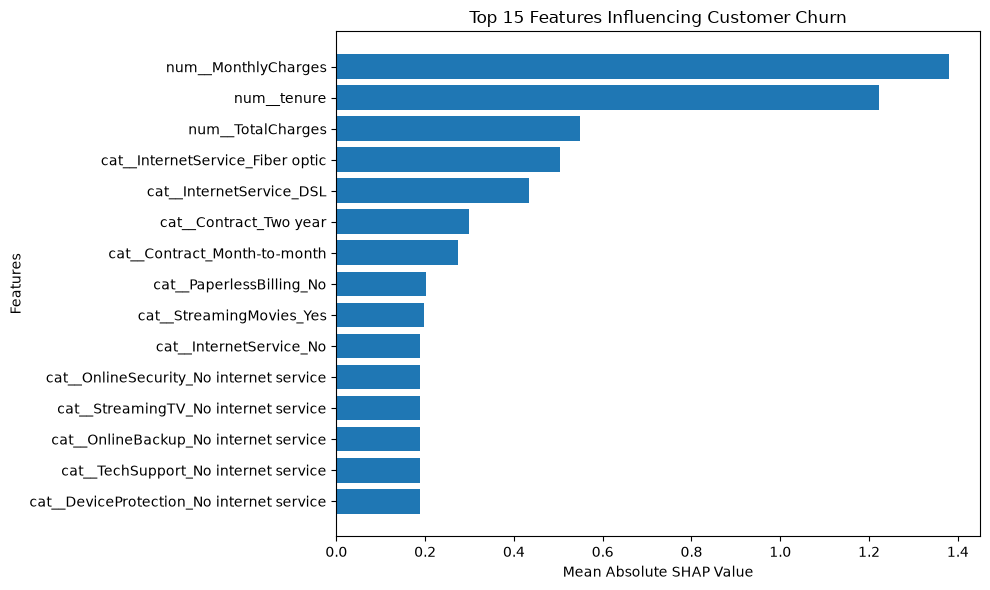

In [28]:
import matplotlib.pyplot as plt

top_features = feature_importance_df.head(15).sort_values(
    by="mean_absolute_shap",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"],
    top_features["mean_absolute_shap"]
)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [29]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(best_logistic_model, MODEL_DIR / "churn_model.joblib")

print("Model saved successfully!")

Model saved successfully!
